# 01 · Understand the trade data

**Question: what changes in motorcycle trade, and which patterns survive checks on units, coverage and seasonality?**

I use Belgium, Germany, France, the Netherlands, Italy and Spain over 2018–2025. This gives a small European comparison around Belgium. It is not a representative sample of Europe.

- A **reporter** submits the data. Imports enter it; exports leave it. The partner is the other side of the trade.
- A row is one month × reporter × partner × engine category × direction. It can contain many transactions. Trade is not retail sales.
- The three categories cover combustion motorcycles above 380–500 cc, 500–800 cc and 800 cc. **They cover only part of the market.**

The practical aim is to describe trade, compare planning forecasts and decide which records deserve checking. Bold sentences give the findings and decisions.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from moto_study.decoding import MEASURES, ROUTE, cell_at, decode_trade
from moto_study.io import (
    manifest,
    project_root,
    read_bytes,
    save_prepared,
    select_source,
    verify_sources,
)
from moto_study.plots import PRODUCT_LABELS, set_style, short_label
from moto_study.quality import (
    assert_quality,
    country_totals,
    prepare_trade,
    quality_checks,
    route_coverage,
)

root = project_root()
metadata = manifest(root)
set_style()
pd.options.display.float_format = "{:,.2f}".format

## 1. Start with one row

Belgium's imports from Japan, January 2024, above 800 cc. I compare the encoded source cells with the decoded table before combining files.

In [2]:
source = select_source(root, reporter="BE", product="87115000", year=2024)
payload = json.loads(read_bytes(root, source))
selection = dict(
    freq="M", reporter="BE", partner="JP", product="87115000", flow="1", time="2024-01"
)
raw_cells = []
for indicator, column in MEASURES.items():
    cell = cell_at(payload, {**selection, "indicators": indicator})
    raw_cells.append(
        {"measure": column, "value": cell["value"], "status": cell["status"] or "No flag supplied"}
    )
display(pd.DataFrame(raw_cells))
decoded = decode_trade(payload, source)
row = decoded.loc[
    decoded.partner.eq("JP") & decoded.flow.eq("1") & decoded.month.eq("2024-01-01")
].iloc[0]
assert all(row[item["measure"]] == item["value"] for item in raw_cells)
display(
    pd.Series(
        {
            "EUR": row.value_eur,
            "kg": row.mass_100kg * 100,
            "items": row.supplementary_quantity,
            "EUR/kg": row.value_eur / (row.mass_100kg * 100),
            "EUR/item": row.value_eur / row.supplementary_quantity,
        },
        name="January 2024",
    )
)

,measure,value,status
0,value_eur,"4,928,487.00",No flag supplied
1,mass_100kg,"1,284.09",No flag supplied
2,supplementary_quantity,554.00,No flag supplied


EUR        4,928,487.00
kg           128,409.00
items            554.00
EUR/kg            38.38
EUR/item       8,896.19
Name: January 2024, dtype: float64

**The measurements match. Mass is reported in 100 kg units; I multiply it by 100 once.** Supplementary quantity uses items for these codes. EUR/kg and EUR/item are trade averages, not retail prices. A different mix of motorcycles can change both. [Units and sources](../docs/DATA_SOURCES.md).

“No flag supplied” means no annotation. It does not certify the data.

## 2. Check scope and reconcile totals

**I keep two tables:** individual partner routes for investigation, and official `WORLD` totals for national forecasts. Adding both would double-count trade. Unallocated partners belong in national totals but cannot identify a route.

In [3]:
verified = verify_sources(root)
raw = pd.concat(
    [decode_trade(json.loads(read_bytes(root, s)), s) for s in metadata["sources"]],
    ignore_index=True,
)
trade, excluded, quarantine = prepare_trade(raw, metadata["scope"])
totals = country_totals(raw, trade)  # Checks value, mass and item counts against WORLD.
checks = quality_checks(trade, verified.source_id)
assert_quality(checks)
assert quarantine.empty
display(checks[["check", "violations", "status"]])
display(excluded.exclusion_reason.value_counts().rename("rows"))
display(
    trade.loc[trade.partner.isin(["XS", "XK", "XC", "XL"])]
    .groupby("partner_label")
    .value_eur.agg(["count", "sum"])
    .rename(index=short_label)
)
example = totals.loc[
    totals.reporter.eq("BE")
    & totals["product"].eq("87115000")
    & totals.flow.eq("1")
    & totals.month.between("2023-03-01", "2023-05-01")
]
display(
    example[
        [
            "month",
            "value_eur",
            "known_partner_value_eur",
            "unallocated_value_eur",
            "known_value_share",
        ]
    ]
)
display(
    Markdown(
        f"**{len(trade):,} route observations and {len(totals):,} national totals pass the checks. "
        "In these Belgian months, unallocated value is too large to ignore.**"
    )
)

,check,violations,status
0,Unique observation grain,0,PASS
1,Known source reference,0,PASS
2,Detailed CN8 identifiers,0,PASS
3,Individual partner codes,0,PASS
4,Valid direction codes,0,PASS
5,Finite nonnegative measures,0,PASS
6,Mass conversion,0,PASS
7,Undefined ratio at zero/missing mass,0,PASS
8,Positive-mass ratio identity,0,PASS
9,Observation flags preserved,0,PASS


exclusion_reason
overlapping_total      31066
unallocated_partner      287
Name: rows, dtype: int64

,count,sum
partner_label,,
Ceuta,469,"14,485,792.00"
Kosovo,88,"2,252,367.00"
Melilla,407,"9,079,865.00"
Serbia,434,"55,967,788.00"


,month,value_eur,known_partner_value_eur,unallocated_value_eur,known_value_share
2236,2023-03-01,"72,723,079.00","35,357,424.00","37,365,655.00",0.49
2272,2023-04-01,"59,398,030.00","27,251,191.00","32,146,839.00",0.46
2308,2023-05-01,"61,466,611.00","25,117,721.00","36,348,890.00",0.41


**82,050 route observations and 3,456 national totals pass the checks. In these Belgian months, unallocated value is too large to ignore.**

**Serbia, Kosovo, Ceuta and Melilla remain valid partners even though their Eurostat codes differ from ISO codes.** Unknown codes stop preparation for review. File hashes check integrity; reconciliation checks that the chosen scope adds up.

In [4]:
coverage = route_coverage(trade)
flags = [name + "_status" for name in MEASURES.values()]
display(
    pd.Series(
        {
            "missing source measurements": int(trade[list(MEASURES.values())].isna().sum().sum()),
            "flagged measurements": int(trade[flags].ne("").sum().sum()),
            "zero mass rows": int(trade.net_mass_kg.eq(0).sum()),
            "routes with internal gaps": int(coverage.internal_gaps.gt(0).sum()),
            "median internal gaps per route": float(coverage.internal_gaps.median()),
        }
    )
)
display(
    trade.loc[trade.net_mass_kg.eq(0)]
    .groupby("reporter_label")
    .size()
    .rename("zero mass rows")
    .rename(index=short_label)
)

missing source measurements          0.00
flagged measurements                 0.00
zero mass rows                   3,281.00
routes with internal gaps        2,059.00
median internal gaps per route      19.00
dtype: float64

reporter_label
Belgium           2
France            7
Germany          10
Italy             1
Netherlands    3256
Spain             5
Name: zero mass rows, dtype: int64

**Zero mass stays zero; its EUR/kg stays undefined. Missing months stay missing.** Neither means an error automatically. Gaps and short histories will limit anomaly scoring.

### Check whether the measurements make sense together

Reconciliation alone can miss a wrong source measurement. I inspect a route with an implausibly small weight per reported item.

In [5]:
quantity_check = trade.loc[
    trade.reporter.eq("BE")
    & trade.partner.eq("IT")
    & trade["product"].eq("87115000")
    & trade.flow.eq("1")
    & trade.month.eq("2024-03-01")
]
display(
    quantity_check[
        ["value_eur", "net_mass_kg", "items_reported", "mass_kg_per_item", "value_eur_per_item"]
    ].T
)

,62888
value_eur,"2,265,128.00"
net_mass_kg,"32,154.00"
items_reported,"1,664,080.00"
mass_kg_per_item,0.02
value_eur_per_item,1.36


**Belgium's imports from Italy report 1,664,080 items but only 32,154 kg: about 0.019 kg per item. That is not credible for motorcycles above 800 cc.** The absence of a source flag did not catch it. I keep the source unchanged and would request clarification. **Item counts remain a diagnostic, not a forecast target or a verified measure of sales volume.**

## 3. Describe size, growth and concentration

Large flows can hide smaller ones. I inspect national monthly values on a log scale: equal distances then mean proportional differences. This is also the level I will forecast.

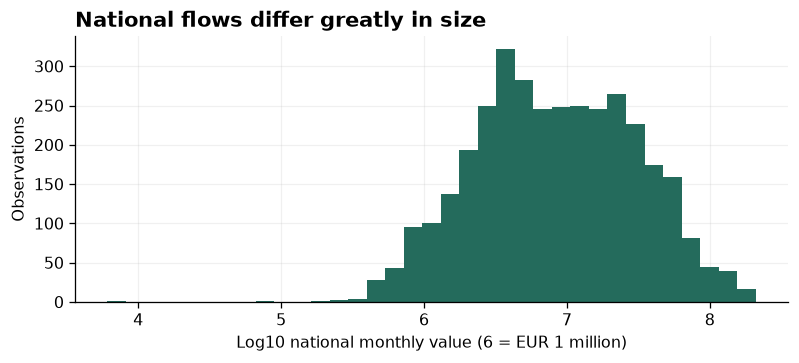

0.50     8,036,039.50
0.90    46,380,355.50
0.99   131,900,903.90
Name: national monthly EUR, dtype: float64

In [6]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(np.log10(totals.value_eur.where(totals.value_eur.gt(0)).dropna()), bins=35)
ax.set(
    xlabel="Log10 national monthly value (6 = EUR 1 million)",
    ylabel="Observations",
    title="National flows differ greatly in size",
)
plt.show()
display(totals.value_eur.quantile([0.5, 0.9, 0.99]).rename("national monthly EUR"))

**I will compare raw and log forecasts and evaluate both in EUR.** A large observation is not enough to call it abnormal.

For Belgium, I compare national growth with a fixed set of routes observed in all 24 months of 2024–2025. This separates country totals from changing partner composition.

In [7]:
be = trade.loc[trade.reporter.eq("BE") & trade.flow.eq("1") & trade.month.ge("2024-01-01")].copy()
fixed = be.groupby(ROUTE).month.transform("size").eq(24)
world_be = totals.loc[
    totals.reporter.eq("BE") & totals.flow.eq("1") & totals.month.ge("2024-01-01")
]
annual = pd.DataFrame(
    {
        "national EUR": world_be.groupby(world_be.month.dt.year).value_eur.sum(),
        "known partner EUR": be.groupby(be.month.dt.year).value_eur.sum(),
        "continuous route EUR": be.loc[fixed].groupby(be.loc[fixed].month.dt.year).value_eur.sum(),
    }
)
display(annual)
growth = (annual.loc[2025] / annual.loc[2024] - 1) * 100
display(growth.rename("2025 growth (%)"))
display(
    Markdown(
        f"**National imports grow {growth['national EUR']:.2f}%; continuously reported routes grow "
        f"{growth['continuous route EUR']:.2f}%. These answer different questions.** "
        "The fixed group favours persistent routes; it does not replace the national result."
    )
)

,national EUR,known partner EUR,continuous route EUR
month,,,
2024,"601,201,035.00","601,201,035.00","531,627,529.00"
2025,"624,765,126.00","617,280,740.00","583,485,217.00"


national EUR           3.92
known partner EUR      2.67
continuous route EUR   9.75
Name: 2025 growth (%), dtype: float64

**National imports grow 3.92%; continuously reported routes grow 9.75%. These answer different questions.** The fixed group favours persistent routes; it does not replace the national result.

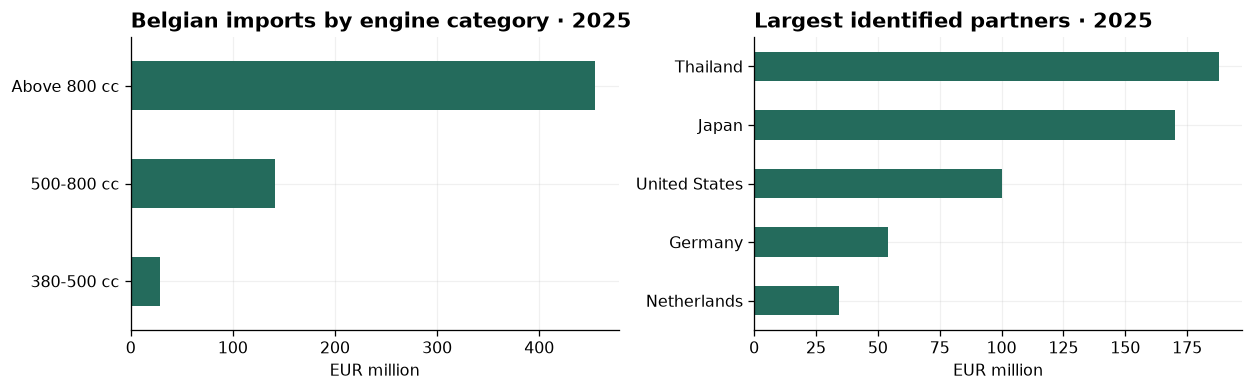

**The two largest identified partners represent 57.3% of national import value. A few partner changes can therefore move the total.**

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
category = world_be.loc[world_be.month.dt.year.eq(2025)].groupby("product").value_eur.sum()
category.rename(index=PRODUCT_LABELS).div(1e6).plot.barh(ax=axes[0])
partners = be.loc[be.month.dt.year.eq(2025)].groupby("partner_label").value_eur.sum().nlargest(5)
partners.rename(index=short_label).sort_values().div(1e6).plot.barh(ax=axes[1])
axes[0].set(title="Belgian imports by engine category · 2025", xlabel="EUR million", ylabel="")
axes[1].set(title="Largest identified partners · 2025", xlabel="EUR million", ylabel="")
plt.tight_layout()
plt.show()
share = partners.iloc[:2].sum() / world_be.loc[world_be.month.dt.year.eq(2025), "value_eur"].sum()
display(
    Markdown(
        f"**The two largest identified partners represent {share:.1%} of national import value. "
        "A few partner changes can therefore move the total.**"
    )
)

## 4. Test the seasonal expectation

Imports may rise before the riding season. I compare the **average month** in March–June with January, February and December, within each country-year. This avoids comparing four months' totals with three. I repeat the check on routes present all year.

,value ratio,mass ratio
reporter,,
BE,1.74,1.67
DE,1.47,1.46
ES,1.23,1.25
FR,1.46,1.46
IT,1.36,1.39
NL,1.30,1.30


,national,year-round routes
March–June exceeds winter,,
value_eur,33,33
net_mass_kg,32,32


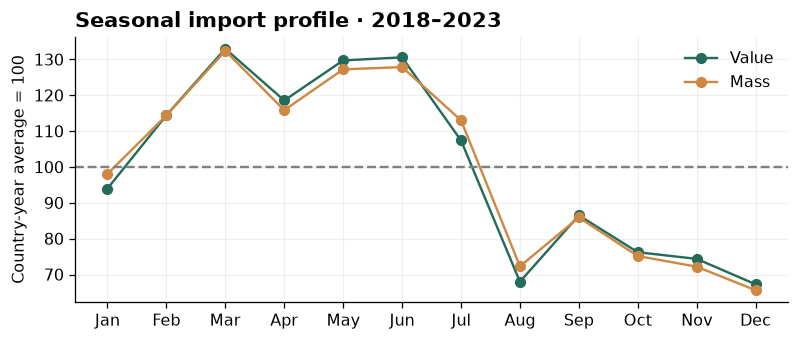

**Spring/early summer exceeds winter in 33/36 country-years. The fixed-route check also shows a seasonal pattern.** I will test seasonal forecasts and remove recurring annual patterns before scoring anomalies. This does not establish a weather or retail-sales effect.

In [9]:
imports = totals.loc[totals.flow.eq("1") & totals.month.dt.year.le(2023)]
season = imports.groupby(["reporter", "month"])[["value_eur", "net_mass_kg"]].sum().reset_index()
route_imports = trade.loc[trade.flow.eq("1") & trade.month.dt.year.le(2023)].copy()
route_imports["year"] = route_imports.month.dt.year
complete = route_imports.groupby([*ROUTE, "year"]).month.transform("size").eq(12)
cohort = (
    route_imports.loc[complete]
    .groupby(["reporter", "month"])[["value_eur", "net_mass_kg"]]
    .sum()
    .reset_index()
)


def seasonal_ratios(frame):
    frame = frame.assign(year=frame.month.dt.year, calendar_month=frame.month.dt.month)
    spring = (
        frame.loc[frame.calendar_month.between(3, 6)]
        .groupby(["reporter", "year"])[["value_eur", "net_mass_kg"]]
        .mean()
    )
    winter = (
        frame.loc[frame.calendar_month.isin([1, 2, 12])]
        .groupby(["reporter", "year"])[["value_eur", "net_mass_kg"]]
        .mean()
    )
    return spring / winter


ratios = seasonal_ratios(season)
display(
    ratios.groupby("reporter")
    .median()
    .rename(columns={"value_eur": "value ratio", "net_mass_kg": "mass ratio"})
)
display(
    pd.DataFrame(
        {"national": ratios.gt(1).sum(), "year-round routes": seasonal_ratios(cohort).gt(1).sum()}
    ).rename_axis("March–June exceeds winter")
)
indexed = season.assign(year=season.month.dt.year)
for col in ["value_eur", "net_mass_kg"]:
    indexed[col] = 100 * indexed[col] / indexed.groupby(["reporter", "year"])[col].transform("mean")
profile = indexed.groupby(indexed.month.dt.month)[["value_eur", "net_mass_kg"]].mean()
profile.rename(columns={"value_eur": "Value", "net_mass_kg": "Mass"}).plot(
    figsize=(8, 3), marker="o"
)
plt.axhline(100, color="grey", linestyle="--")
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
)
plt.ylabel("Country-year average = 100")
plt.xlabel("")
plt.title("Seasonal import profile · 2018–2023")
plt.show()
display(
    Markdown(
        f"**Spring/early summer exceeds winter in {int(ratios.value_eur.gt(1).sum())}/{len(ratios)} "
        "country-years. The fixed-route check also shows a seasonal pattern.** "
        "I will test seasonal forecasts and remove recurring annual patterns before scoring anomalies. "
        "This does not establish a weather or retail-sales effect."
    )
)

### Return to one peak

I compare the Belgian–Japanese route in June 2024 with June 2023. The same calendar month is a better comparator than winter.

In [10]:
route = trade.loc[
    trade.reporter.eq("BE")
    & trade.partner.eq("JP")
    & trade["product"].eq("87115000")
    & trade.flow.eq("1")
]
cols = ["value_eur", "net_mass_kg", "items_reported", "unit_value_eur_per_kg", "value_eur_per_item"]
pair = route.loc[route.month.isin(pd.to_datetime(["2023-06-01", "2024-06-01"]))].set_index("month")[
    cols
]
display(pair)
display(((pair.iloc[1] / pair.iloc[0] - 1) * 100).rename("year-on-year change (%)"))
save_prepared(root, trade, checks, totals)

,value_eur,net_mass_kg,items_reported,unit_value_eur_per_kg,value_eur_per_item
month,,,,,
2023-06-01,"3,532,802.00","80,432.00",313.00,43.92,"11,286.91"
2024-06-01,"13,370,050.00","325,813.00","1,359.00",41.04,"9,838.15"


value_eur               278.45
net_mass_kg             305.08
items_reported          334.19
unit_value_eur_per_kg    -6.57
value_eur_per_item      -12.84
Name: year-on-year change (%), dtype: float64

**The value jump accompanies more mass and more items; EUR/kg falls. I retain the peak.** The arithmetic is consistent, but it cannot identify the commercial cause. Next: [forecast the national totals](02_monthly_forecasts.ipynb).